# YOLO 11 – End-to-End Training & Evaluation  


# Required Libraries Installation

In [ ]:
!pip uninstall tensorboard -y
!pip install tensorboard
!pip install ultralytics

Found existing installation: tensorboard 2.18.0
Uninstalling tensorboard-2.18.0:
  Successfully uninstalled tensorboard-2.18.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 72.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.18.0 requires tensorboard<2.19,>=2.18, but you have tensorboard 2.19.0 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 120.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 96.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import torch, ultralytics
print('PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
print('Ultralytics:', ultralytics.__version__)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.6.0+cu124 | CUDA: True
Ultralytics: 8.3.128


# Nvidia GPU Check

In [ ]:
!nvidia-smi

Wed May  7 11:59:46 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       2MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Importing Required Libraries

In [ ]:
import os
import json
import shutil
import matplotlib.pyplot as plt
import cv2
from tqdm import tqdm
import pandas as pd
import numpy as np
import os, random, cv2, json, yaml, math, numpy as np, pandas as pd
from pathlib import Path
from ipywidgets import interact
from IPython.display import HTML, display, Video


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Data exploration & sanity checks

265 training images  |  265 label files


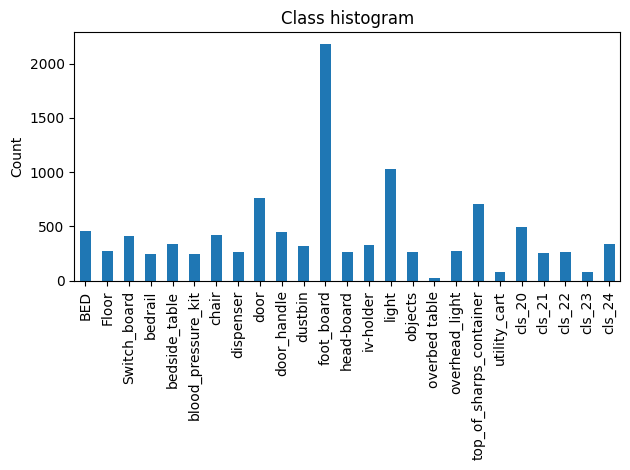

In [ ]:
# ── paths ────────────────────────────────────────────────────────
BASE      = Path('/content/drive/MyDrive/R&D/CV')
DATA_DIR  = BASE/'data'/'Batch_1.v3i.yolov11'
IMG_DIR   = DATA_DIR/'train'/'images'
LBL_DIR   = DATA_DIR/'train'/'labels'

# ── 20-class roster (extend if your dataset truly has more) ─────
CLASS_NAMES = [
    'BED', 'Floor', 'Switch_board', 'bedrail', 'bedside_table',
    'blood_pressure_kit', 'chair', 'dispenser', 'door', 'door_handle',
    'dustbin', 'foot_board', 'head-board', 'iv-holder', 'light', 'objects',
    'overbed table', 'overhead_light', 'top_of_sharps_container', 'utility_cart'
]

# ── gather files ────────────────────────────────────────────────
img_files = list(IMG_DIR.glob('*.jpg'))
lbl_files = list(LBL_DIR.glob('*.txt'))
print(f'{len(img_files):,} training images  |  {len(lbl_files):,} label files')

# ── class histogram ─────────────────────────────────────────────
classes = []
for txt in lbl_files:
    with open(txt) as f:
        classes.extend([int(line.split()[0]) for line in f])

if classes:
    counts = pd.Series(classes).value_counts().sort_index()
    tick_labels = [
        CLASS_NAMES[i] if i < len(CLASS_NAMES) else f'cls_{i}'
        for i in counts.index
    ]
    ax = counts.plot.bar()
    ax.set_xticklabels(tick_labels, rotation=90)
    plt.title('Class histogram'); plt.ylabel('Count'); plt.tight_layout(); plt.show()
else:
    print('⚠️  No labels found – check label files.')

# ── single-image renderer (bbox + optional polygon) ─────────────
def render_sample(img_path, alpha=0.40):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    txt_path = LBL_DIR / f'{img_path.stem}.txt'

    with open(txt_path) as f:
        for line in f:
            parts = list(map(float, line.split()))
            cls, cx, cy, bw, bh, *poly = parts
            cls = int(cls)

            # bbox
            x, y = cx*w, cy*h; bw, bh = bw*w, bh*h
            p1 = (int(x-bw/2), int(y-bh/2)); p2 = (int(x+bw/2), int(y+bh/2))
            cv2.rectangle(img, p1, p2, (0,255,0), 2)

            label = CLASS_NAMES[cls] if cls < len(CLASS_NAMES) else f'cls_{cls}'
            cv2.putText(img, label, p1, cv2.FONT_HERSHEY_SIMPLEX,
                        0.55, (255,255,255), 2)

            # polygon mask (YOLO-Seg)
            if poly:
                pts = np.array(poly).reshape(-1,2)
                pts[:,0] *= w; pts[:,1] *= h
                overlay = img.copy()
                cv2.fillPoly(overlay, [pts.astype(int)], (0,128,255))
                img = cv2.addWeighted(overlay, alpha, img, 1-alpha, 0)

    _, enc = cv2.imencode('.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    display(HTML(f'<img src="data:image/jpeg;base64,{enc.tobytes().hex()}" width=400>'))


# preview 9 random examples
sample_paths = random.sample(img_files, min(9, len(img_files)))

# Visualise polygons (YOLO-Seg format)

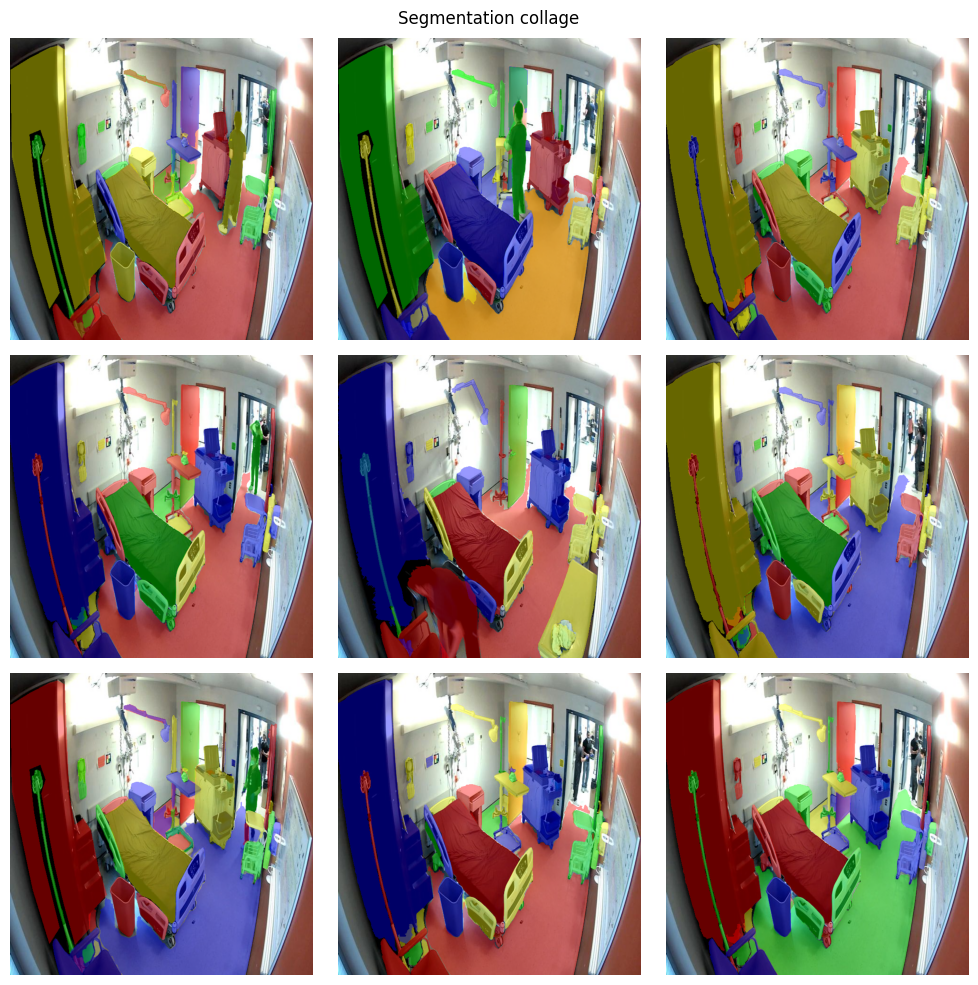

In [ ]:
def poly_to_pts(poly, w, h):
    """Turn 'x1 y1 x2 y2 ... xn yn' (norm) ➜ Nx2 pixel array"""
    coords = list(map(float, poly.split()))
    pts = np.array(coords).reshape(-1, 2)
    pts[:, 0] *= w; pts[:, 1] *= h
    return pts.astype(int)

def draw_mask(img, pts, colour):
    overlay = img.copy()
    cv2.fillPoly(overlay, [pts], colour)
    return cv2.addWeighted(overlay, 0.4, img, 0.6, 0)

def show_seg_collage(img_dir, lbl_dir, n=9, title='Segmentation collage'):
    paths = random.sample(list(img_dir.glob('*.jpg')), n)
    plt.figure(figsize=(10,10))
    for i, p in enumerate(paths, 1):
        img  = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h,w,_ = img.shape
        txt   = lbl_dir / (p.stem + '.txt')
        colours = [(0,255,0),(255,0,0),(0,0,255),(255,255,0)]
        with open(txt) as f:
            for line in f:
                cls, *poly = line.split()
                pts = poly_to_pts(' '.join(poly), w, h)
                img = draw_mask(img, pts, random.choice(colours))
        plt.subplot(3,3,i); plt.imshow(img); plt.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.show()

train_imgs = DATA_DIR/'train/images'
train_lbls = DATA_DIR/'train/labels'
show_seg_collage(train_imgs, train_lbls)


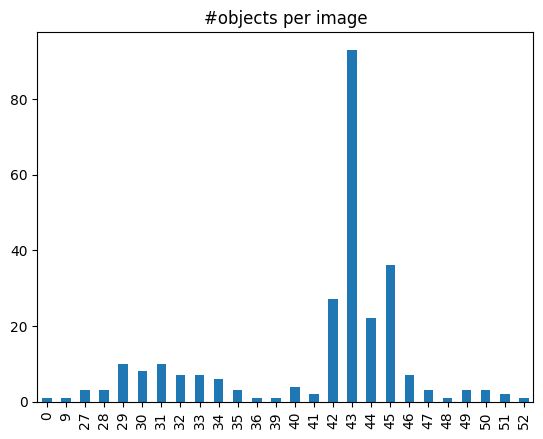

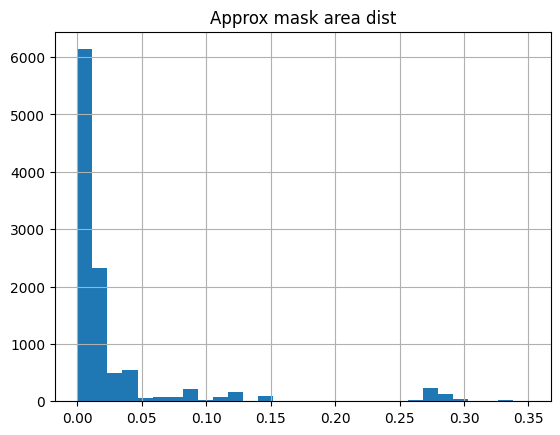

In [ ]:
mask_counts, mask_areas = [], []

for txt in (DATA_DIR/'train/labels').glob('*.txt'):
    with open(txt) as f:
        polys = [l.split()[1:] for l in f]
    mask_counts.append(len(polys))
    for p in polys:
        pts = np.array(list(map(float, p))).reshape(-1,2)
        xs, ys = pts[:,0], pts[:,1]
        mask_areas.append((xs.max()-xs.min())*(ys.max()-ys.min()))

pd.Series(mask_counts).value_counts().sort_index().plot.bar()
plt.title('#objects per image'); plt.show()

pd.Series(mask_areas).hist(bins=30); plt.title('Approx mask area dist'); plt.show()


# Load YOLO 11 custom hyper-params

In [ ]:
from ultralytics import YOLO, settings

# 🔸 Training hyper-parameters
EPOCHS = 50
IMG    = 960        # big enough for hospital rooms
BATCH  = 8
LR0    = 0.001
WEIGHTS= 'yolo11l-seg'   # COCO-pretrained medium model
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)
model = YOLO(WEIGHTS)   # auto-downloads on first use
print('Model loaded:', model.model.yaml['model'])


✅ Model loaded
  · classes : 80
  · stride  : tensor([ 8., 16., 32.])


TypeError: unhashable type: 'slice'

# Model Training

In [ ]:
EPOCHS, BATCH, IMG, LR = 60, 8, 960, 0.0007

model.train(
    task='segment',
    data=str(yaml_file),
    epochs=EPOCHS,
    imgsz=IMG,
    batch=BATCH,
    lr0=LR,
    project=EXP_DIR.parent,   # runs/segment
    name='yolo11m_seg_clean',
    device=device,
    exist_ok=True,
)


In [ ]:
%load_ext tensorboard
%tensorboard --logdir {EXP_DIR.parent}


# Training & Evaluation Graphs

In [ ]:
# ⬛ Plot training curves and show evaluation artefacts
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
RUN_DIR = EXP_DIR.parent/'yolo11m_seg_clean'       # adjust if you changed the run-name

# ── 1. Loss / metric curves ──────────────────────────────────────────────
hist = pd.read_csv(RUN_DIR/'results.csv')          # auto-written by Ultralytics
fig, ax = plt.subplots(1, 3, figsize=(18,4))

ax[0].plot(hist['epoch'], hist['train/box_loss'], label='box');
ax[0].plot(hist['epoch'], hist['train/mask_loss'], label='mask');
ax[0].set_title('Train loss'); ax[0].legend()

ax[1].plot(hist['epoch'], hist['metrics/precision(B)'], label='P');
ax[1].plot(hist['epoch'], hist['metrics/recall(B)'],    label='R');
ax[1].set_title('Precision / Recall'); ax[1].legend()

ax[2].plot(hist['epoch'], hist['metrics/mAP50(M)']);
ax[2].set_title('mAP-50 (mask)');
plt.show()

# ── 2. PR curve, confusion matrix, F1 curve produced by `val(plots=True)` ──
eval_dir = RUN_DIR/'val'  # auto-created by last val() call
for png in ['PR_curve.png', 'confusion_matrix.png', 'F1_curve.png']:
    display(Image.open(eval_dir/png))


# Video inference with masks

In [ ]:
VIDEO_IN  = '/content/sample_hallway.mp4'   # upload
RUN_DIR   = RESULTS_DIR/'seg_video'
pred = model.predict(
    source=VIDEO_IN,
    model=str(best),
    task='segment',
    imgsz=IMG,
    save=True,
    project=str(RUN_DIR.parent),
    name=RUN_DIR.name,
    device=device,
)
out_vid = next((RUN_DIR).glob('*.mp4'))
Video(str(out_vid), embed=True, width=640)


In [ ]:
from ultralytics import YOLO
from IPython.display import Video, display, HTML
import cv2, matplotlib.pyplot as plt, numpy as np, random, shutil, glob

best_ckpt = RUN_DIR/'weights'/'best.pt'
infer_model = YOLO(str(best_ckpt))

# ── 1. Single-image inference + overlay ─────────────────────────────────
def infer_image(img_path, imgsz=960, conf=0.25):
    r = infer_model.predict(source=img_path, imgsz=imgsz, conf=conf, task='segment', save=False, verbose=False)[0]
    plotted = r.plot()  # returns BGR
    plt.figure(figsize=(6,6)); plt.imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)); plt.axis('off')
    plt.title(f"Detections @ conf>{conf}"); plt.show()

sample_img = random.choice(glob.glob(str(DATA_DIR/'valid/images/*.jpg')))
infer_image(sample_img)

# ── 2. Video inference – auto-embed ─────────────────────────────────────
VIDEO_IN  = '/content/sample_hallway.mp4'   # upload or Drive path
OUT_DIR   = RESULTS_DIR/'video_seg'
pred = infer_model.predict(
    source=VIDEO_IN,
    imgsz=960,
    conf=0.25,
    task='segment',
    save=True,
    project=str(OUT_DIR.parent),
    name=OUT_DIR.name,
    stream=False,
    device=device
)
out_mp4 = next((OUT_DIR).glob('*.mp4'))
display(Video(str(out_mp4), embed=True, width=640))
